In [1]:
print(1)

1


In [309]:
import math
import numpy as np
import matplotlib.pyplot as plt
import random
%matplotlib inline

In [13]:
def f(x):
    return 3*x**2 - 4*x + 5

In [14]:
f(3)

20

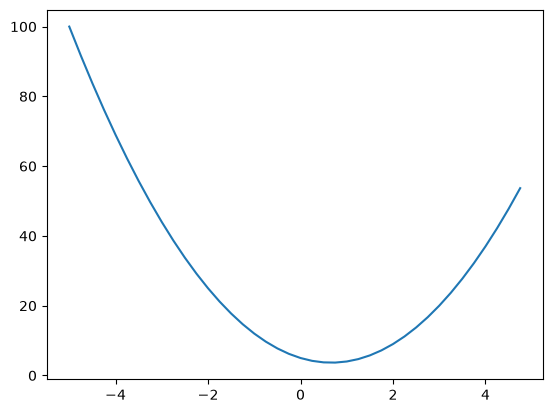

In [15]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs,ys)

In [25]:
h = 0.0000001
x = 2/3
(f(x + h) - f(x))/h

2.9753977059954195e-07

In [28]:
a = 2.0
b = -3.0
c = 10.0
d = a*b + c
print(d)

4.0


In [34]:
h=0.0001

# inputs
a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
b += h
d2 = a*b + c
print('d1', d1)
print('d2', d2)
print('slope', (d2-d1)/h)

d1 4.0
d2 4.0002
slope 2.0000000000042206


In [277]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label
        
    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        
        def _backward():
            self.grad += out.grad * 1.0
            other.grad += out.grad * 1.0
            
        out._backward = _backward
        return out

    def __radd__(self, other):
        return self + other
    
    def __sub__(self, other):
        return self + (-other)

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        
        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data
            
        out._backward = _backward
        return out
        
    def __rmul__(self, other):
        return self*other

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only int and float for now"
        out = Value(self.data**other, (self, ), f'**{other}')

        def _backward():
            self.grad += out.grad * (other*self.data**(other-1))
            
        out._backward = _backward
        
        return out

    def __truediv__(self, other):
        return self * other**-1

    def __neg__(self):
        return self * -1
    
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) +1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad += out.grad * ( 1 - t**2 )
            
        out._backward = _backward
        return out

    def exp(self):
        x = self.data
        t = math.exp(x)
        out = Value(t, (self, ), 'exp')

        def _backward():
            self.grad += out.grad * t
            
        out._backward = _backward
        return out
    
    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        
        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()


In [278]:
a = Value(2.0)
b = Value(4.0)
a-b

Value(data=-2.0)

In [268]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir':'LR'}) # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad, ), shape="record")
        if n._op:
            dot.node(name = uid + n._op, label = n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot
        

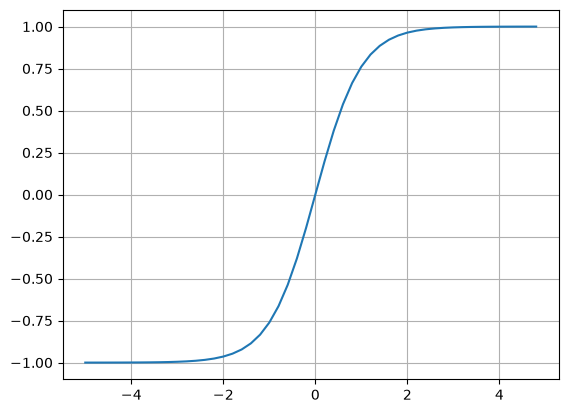

In [241]:
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2)));plt.grid()

In [285]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias
b = Value(6.8813735870195432, label='b')

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label='o'
o.backward()

In [283]:
a = 0.01
delta = -1
w1.data = w1.data + a * delta
w2.data = w2.data + a * delta

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label='o'

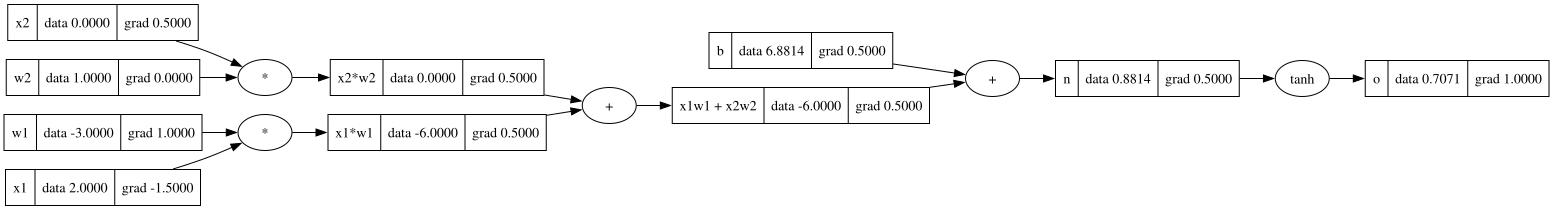

In [286]:
draw_dot(o)

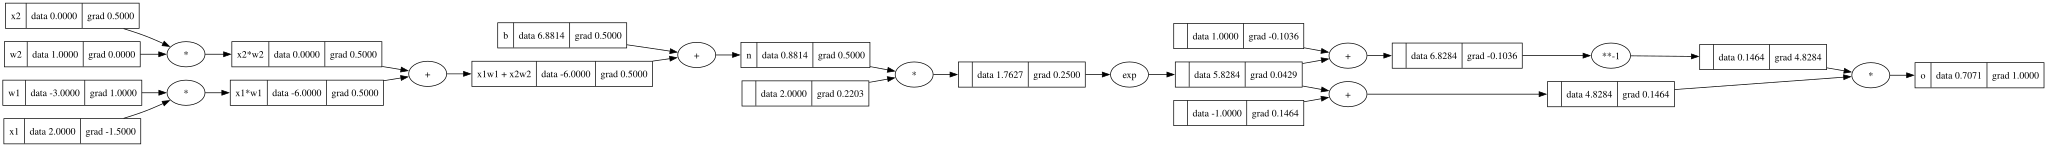

In [287]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias
b = Value(6.8813735870195432, label='b')

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'
# ----
e = (2*n).exp()
o = (e-1)/(e+1)
# ----
o.label='o'
o.backward()
draw_dot(o)

In [289]:
import torch
x1 = torch.Tensor([2.0]).double(); x1.requires_grad=True
x2 = torch.Tensor([0.0]).double(); x2.requires_grad=True
w1 = torch.Tensor([-3.0]).double(); w1.requires_grad=True
w2 = torch.Tensor([1.0]).double(); w2.requires_grad=True
b = torch.Tensor([6.8813735870195432]).double(); b.requires_grad=True

n = x1*w1 + x2*w2 +b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print("---")
print("x2", x2.grad.item())
print("w2", w2.grad.item())
print("x1", x1.grad.item())
print("w1", w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [506]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
        # w * x + b
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]
        
class Layer:
    def __init__(self, nin, nout): 
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs
        
    def parameters(self):
        return [ p for neuron in self.neurons for p in neuron.parameters() ]

class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [ p for layer in self.layers for p in layer.parameters() ]



In [522]:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])
n(x)

Value(data=0.15021923911604187)

In [523]:
n.parameters()

[Value(data=-0.47394322720871895),
 Value(data=-0.6666834854766504),
 Value(data=0.5778678203200267),
 Value(data=-0.4489245737319505),
 Value(data=-0.5477161872328375),
 Value(data=-0.12377967222520603),
 Value(data=-0.8126997455419871),
 Value(data=-0.8325477271564921),
 Value(data=-0.8159995320998814),
 Value(data=0.7928099585310255),
 Value(data=0.09565547511438188),
 Value(data=-0.846159029202507),
 Value(data=-0.6942666836319982),
 Value(data=-0.8355767775300789),
 Value(data=-0.36632127854452023),
 Value(data=0.19129226087203755),
 Value(data=-0.7338768885545999),
 Value(data=0.969608714040926),
 Value(data=0.43760273922220216),
 Value(data=-0.019065670344051044),
 Value(data=0.7603038292386735),
 Value(data=0.6234575265086508),
 Value(data=-0.4360397795759192),
 Value(data=-0.9854129768715869),
 Value(data=-0.4111938605525358),
 Value(data=-0.03189744742176481),
 Value(data=-0.06468089543098898),
 Value(data=0.3058936741182219),
 Value(data=0.9656953734963645),
 Value(data=0.72

In [524]:
xs = [
    [2.0, 3.0, 1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets



In [525]:
l = 0.05
for k in range(20):
    # forward pass
    ypred = [n(x) for x in xs]
    loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])
    
    # backward pass
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    # update
    for p in n.parameters():
        p.data += -l * p.grad

    print(k, loss.data)


0 3.893655838180827
1 2.7513499229675116
2 2.127448439882649
3 1.813537954188503
4 1.4268606845326588
5 1.133412278524871
6 0.8475085582754646
7 0.5636026138059538
8 0.30097759179051836
9 0.18838843563170105
10 0.155218989787652
11 0.13465775609690775
12 0.11848459695634714
13 0.10546693194070435
14 0.09479179750259238
15 0.08589990608337998
16 0.07839428900603942
17 0.07198573820548675
18 0.06645883553358602
19 0.06165003735178403


In [526]:
loss

Value(data=0.06165003735178403)

In [527]:
ypred

[Value(data=0.8251328380240653),
 Value(data=-0.9492020633726707),
 Value(data=-0.8545737269556354),
 Value(data=0.9143128845327491)]

In [ ]:
|